# Loan Default Prediction: Lending Club Loan Data

**Goal:** predict whether a borrower will **default (Charged Off)** or **fully pay** their loan,
using only information that is available at the time the loan is applied for.

**Steps in this notebook**
1. Load the data and take a 100,000-loan sample
2. Dataset overview
3. Data preparation (duplicates, missing values, leakage, outliers, new features)
4. Exploratory data analysis (EDA)
5. Statistical analysis (sampling and estimation)
6. Encoding, train/test split and scaling
7. Models: Logistic Regression, Random Forest, XGBoost
8. Results and comparison
9. Feature importance
10. Business impact: loan approval strategy
11. Save the results for the dashboard
12. Summary

All graphs are saved into the `images/` folder so they can be used in the report.
The Streamlit dashboard (`app.py`) uses the files saved in Section 11.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

# Chart colours (colour-blind safe)
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GREY_TEXT, GREY_LINE = '#52514e', '#898781'
STATUS_COLORS = {'Fully Paid': BLUE, 'Charged Off': ORANGE}

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': GREY_TEXT,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'axes.axisbelow': True,
    'axes.ymargin': 0.12,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6,
    'xtick.color': GREY_TEXT,
    'ytick.color': GREY_TEXT,
    'text.color': '#0b0b0b',
    'font.size': 10,
    'legend.frameon': False,
})
os.makedirs('images', exist_ok=True)

def save(name):
    """Save the current chart into images/ so it can be used in the report."""
    plt.tight_layout()
    plt.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 1. Load the data

The full Kaggle file (`accepted_2007_to_2018Q4.csv`) is about **1.7 GB** with **2.26 million loans** and **151 columns**.
That is too big to work with comfortably, so we:

1. Read the file in pieces of 200,000 rows.
2. Keep only **finished** loans: `Fully Paid` or `Charged Off`. Loans that are still `Current` have no final outcome yet.
3. Take a random 8% from each piece, then a final random sample of exactly **100,000 loans**.

This step runs only once (about 1 minute). After that, the small sample file is loaded directly.
`random_state=42` makes the sample the same every time.

In [2]:
RAW_FILE = 'data/accepted_2007_to_2018Q4.csv'
SAMPLE_FILE = 'data/loans_sample.csv'
STATUS_FILE = 'data/loan_status_counts.csv'

if not os.path.exists(SAMPLE_FILE):
    pieces, status_counts = [], []
    for chunk in pd.read_csv(RAW_FILE, chunksize=200_000, low_memory=False):
        status_counts.append(chunk['loan_status'].value_counts(dropna=False))
        chunk = chunk[chunk['loan_status'].isin(['Fully Paid', 'Charged Off'])]
        pieces.append(chunk.sample(frac=0.08, random_state=42))

    status = pd.concat(status_counts).groupby(level=0, dropna=False).sum().sort_values(ascending=False)
    status.rename_axis('loan_status').rename('count').to_csv(STATUS_FILE)
    pd.concat(pieces).sample(n=100_000, random_state=42).to_csv(SAMPLE_FILE, index=False)

df = pd.read_csv(SAMPLE_FILE, low_memory=False).copy()   # copy() avoids a pandas performance warning on this wide table
print('Sample shape:', df.shape)

Sample shape: (100000, 151)


**Loan status in the full file** (before sampling):

In [3]:
status = pd.read_csv(STATUS_FILE)
status['loan_status'] = status['loan_status'].fillna('(blank summary rows)')
status['percent'] = (status['count'] / status['count'].sum() * 100).round(2)
print('Total rows in full file:', f"{status['count'].sum():,}")
status

Total rows in full file: 2,260,701


,loan_status,count,percent
0,Fully Paid,1076751,47.63
1,Current,878317,38.85
2,Charged Off,268559,11.88
3,Late (31-120 days),21467,0.95
4,In Grace Period,8436,0.37
5,Late (16-30 days),4349,0.19
6,Does not meet the credit policy. Status:Fully ...,1988,0.09
7,Does not meet the credit policy. Status:Charge...,761,0.03
8,Default,40,0.00
9,(blank summary rows),33,0.00


**Observation:** only `Fully Paid` (47.6%) and `Charged Off` (11.9%) loans have a final outcome.
`Current` loans (38.9%) are still running, so we cannot know yet whether they will default.
The small `Does not meet the credit policy` groups (about 2,700 loans) and the 40 `Default` loans are also left out.
That leaves **1,345,310 finished loans**, from which we sample 100,000.

## 2. Dataset overview

In [4]:
print('Rows:   ', df.shape[0])
print('Columns:', df.shape[1])
print('Numeric columns:', df.select_dtypes('number').shape[1])
print('Text columns:   ', df.select_dtypes(exclude='number').shape[1])
df.head()

Rows:    100000
Columns: 151
Numeric columns: 115
Text columns:    36


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,27260319,NaN,6000.0,6000.0,6000.0,36 months,6.03,182.62,A,A1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,69679986,NaN,6000.0,6000.0,6000.0,36 months,10.78,195.81,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,5950107,NaN,8325.0,8325.0,8325.0,36 months,14.33,285.87,C,C2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,60870161,NaN,20000.0,20000.0,20000.0,60 months,10.99,434.75,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,84094227,NaN,10000.0,10000.0,10000.0,36 months,12.79,335.93,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


**Target variable:** we create a column `default`: **1 = Charged Off** (the borrower did not repay) and **0 = Fully Paid**.

In [5]:
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)
df['loan_status'].value_counts().to_frame().assign(percent=lambda t: (t['count'] / len(df) * 100).round(1))

,count,percent
loan_status,,
Fully Paid,80059,80.1
Charged Off,19941,19.9


## 3. Data preparation

### 3.1 Duplicate records

In [6]:
print('Duplicate rows:    ', df.duplicated().sum())
print('Duplicate loan IDs:', df['id'].duplicated().sum())

Duplicate rows:     0
Duplicate loan IDs: 0


**Observation:** there are no duplicate rows and no repeated loan IDs, so nothing needs to be removed.

### 3.2 Missing values

In [7]:
missing_pct = (df.drop(columns='default').isna().mean() * 100).sort_values(ascending=False)   # the 151 original columns
print('Columns with any missing values: ', (missing_pct > 0).sum())
print('Columns more than 50% missing:   ', (missing_pct > 50).sum())
missing_pct.head(10).round(1).to_frame('missing %')

Columns with any missing values:  103
Columns more than 50% missing:    58


,missing %
member_id,100.0
next_pymnt_d,100.0
orig_projected_additional_accrued_interest,99.7
hardship_payoff_balance_amount,99.6
hardship_last_payment_amount,99.6
hardship_reason,99.6
hardship_type,99.6
hardship_status,99.6
hardship_amount,99.6
deferral_term,99.6


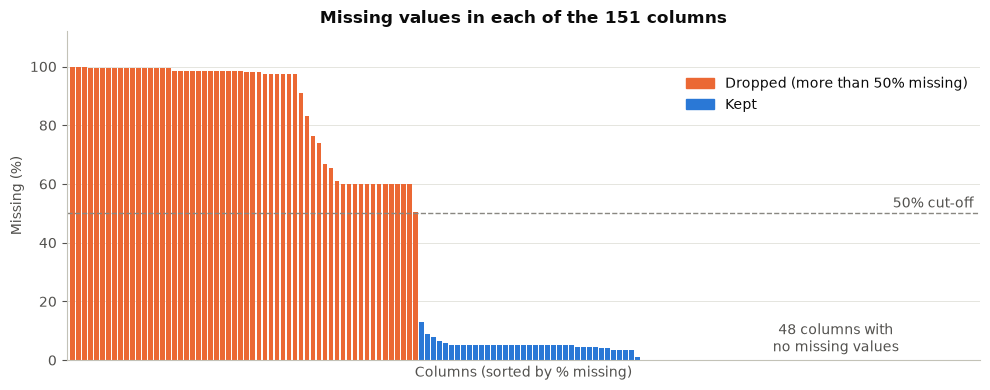

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = [ORANGE if p > 50 else BLUE for p in missing_pct.values]
ax.bar(range(len(missing_pct)), missing_pct.values, color=colors, width=0.8)
no_missing = (missing_pct == 0).sum()
ax.text(len(missing_pct) - no_missing / 2, 3, f'{no_missing} columns with\nno missing values', ha='center', color=GREY_TEXT)
ax.axhline(50, color=GREY_LINE, ls='--', lw=1)
ax.text(len(missing_pct) - 1, 52, '50% cut-off', ha='right', color=GREY_TEXT)
ax.set(title='Missing values in each of the 151 columns', xlabel='Columns (sorted by % missing)',
       ylabel='Missing (%)', xticks=[], xlim=(-1, len(missing_pct)))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=['Dropped (more than 50% missing)', 'Kept'], loc='upper right', bbox_to_anchor=(1, 0.9))
save('01_missing_values')

Columns that are more than half empty carry little information, so we drop them.

In [9]:
drop_cols = missing_pct[missing_pct > 50].index
df = df.drop(columns=drop_cols)
print('Dropped', len(drop_cols), 'columns. Columns left:', df.shape[1])

Dropped 58 columns. Columns left: 94


**Observation:** 103 of the 151 columns have some missing values, and **58 columns are more than 50% empty**,
for example `member_id`, the `hardship_*` and `settlement_*` columns, and the joint-application columns.
These only apply to a small group of borrowers. Dropping them leaves 94 columns.

### 3.3 Remove data leakage and unhelpful columns

Many columns are only known **after** the loan has finished, for example how much was paid back (`total_pymnt`)
or how much was recovered after default (`recoveries`). If we keep them, the model "cheats": it would score
almost perfectly in testing but would be useless for a new applicant. A quick check shows the problem:

In [10]:
df.groupby('loan_status')[['recoveries', 'total_rec_prncp']].mean().round(0)

,recoveries,total_rec_prncp
loan_status,,
Charged Off,1221.0,4388.0
Fully Paid,0.0,14118.0


`recoveries` is above zero **only** for defaulted loans, so it gives away the answer.

We therefore keep only columns that a lender knows **at the time of application**,
and remove IDs, URLs, free text and post-loan information.

In [11]:
keep_cols = ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length',
             'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'purpose',
             'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high',
             'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
             'mort_acc', 'pub_rec_bankruptcies', 'application_type', 'loan_status', 'default']

removed = [c for c in df.columns if c not in keep_cols]
print(len(removed), 'columns removed:')
print(removed)

df = df[keep_cols].copy()
print('\nColumns left:', df.shape[1])

67 columns removed:
['id', 'funded_amnt', 'funded_amnt_inv', 'sub_grade', 'emp_title', 'pymnt_plan', 'url', 'title', 'zip_code', 'addr_state', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'policy_code', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_accts', 'num_rev_tl_bal_gt_0', 'num_sats', 'num_tl_120dpd_2m', 'num_tl_30dp

### 3.4 Convert text to numbers

- `term`: `" 36 months"` becomes `36`
- `emp_length`: `"< 1 year"` becomes `0`, `"10+ years"` becomes `10`
- `home_ownership`: a few loans have the rare values `ANY`, `NONE` or `OTHER`; these rows are removed

In [12]:
df['term'] = df['term'].str.extract(r'(\d+)', expand=False).astype(int)

emp_map = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5,
           '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10}
df['emp_length'] = df['emp_length'].map(emp_map)

rare = ~df['home_ownership'].isin(['MORTGAGE', 'RENT', 'OWN'])
print('Rows removed for rare home_ownership:', rare.sum())
df = df[~rare]

df[['term', 'emp_length', 'home_ownership']].head()

Rows removed for rare home_ownership: 32


,term,emp_length,home_ownership
0,36,2.0,RENT
1,36,2.0,RENT
2,36,3.0,RENT
3,60,0.0,MORTGAGE
4,36,10.0,OWN


### 3.5 Fill the remaining missing values

In [13]:
print('Missing values left:')
print(df.isna().sum()[lambda s: s > 0])

# Every column that still has gaps is numeric, so we fill with the median (not affected by outliers)
num_cols = df.select_dtypes('number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
print('\nMissing values after filling:', df.isna().sum().sum())

Missing values left:
emp_length              5873
dti                       23
revol_util                68
mort_acc                3522
pub_rec_bankruptcies      55
dtype: int64

Missing values after filling: 0


**Observation:** five columns still had gaps: `emp_length` (5,873 rows, about 6%), `mort_acc` (3,522), `revol_util` (68),
`pub_rec_bankruptcies` (55) and `dti` (23). All were filled with the column median.

### 3.6 Outliers

In [14]:
df[['annual_inc', 'dti', 'revol_bal']].describe(percentiles=[0.01, 0.5, 0.99]).round(1)

,annual_inc,dti,revol_bal
count,99968.0,99968.0,99968.0
mean,76047.6,18.3,16297.2
std,57629.5,11.4,21787.5
min,0.0,0.0,0.0
1%,18000.0,1.7,170.0
50%,65000.0,17.6,11145.5
99%,258000.0,38.6,96032.3
max,4695472.0,999.0,1030826.0


Annual income, debt-to-income ratio (DTI) and revolving balance have extreme values.
We **cap** them at the 1st and 99th percentile: values above the 99th percentile are set to the 99th percentile
(and the same for the bottom 1%). No rows are deleted.

annual_inc   capped to 18,000.0 - 258,000.0


dti          capped to 1.7 - 38.6
revol_bal    capped to 170.0 - 96,032.3


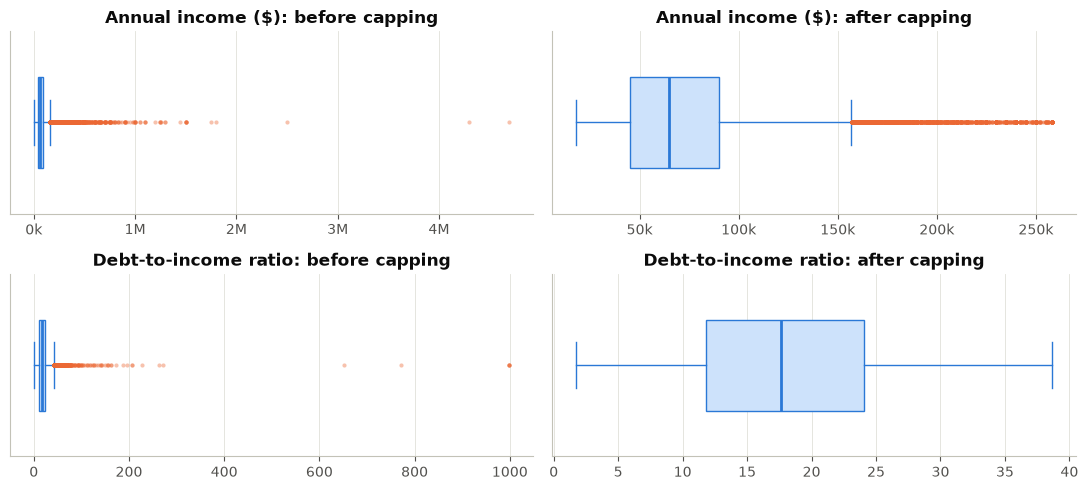

In [15]:
before = df[['annual_inc', 'dti']].copy()

for col in ['annual_inc', 'dti', 'revol_bal']:
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)
    print(f'{col:12s} capped to {low:,.1f} - {high:,.1f}')

fig, axes = plt.subplots(2, 2, figsize=(11, 5))
for row, (col, label) in enumerate([('annual_inc', 'Annual income ($)'), ('dti', 'Debt-to-income ratio')]):
    for ax, data, when in [(axes[row, 0], before[col], 'before'), (axes[row, 1], df[col], 'after')]:
        ax.boxplot(data, orientation='horizontal', widths=0.5, patch_artist=True,
                   boxprops=dict(facecolor='#cde2fb', color=BLUE), medianprops=dict(color=BLUE, lw=2),
                   whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                   flierprops=dict(marker='o', markersize=3, markerfacecolor=ORANGE, markeredgecolor='none', alpha=0.4))
        ax.set(title=f'{label}: {when} capping', yticks=[])
        ax.grid(axis='x')
        ax.grid(axis='y', visible=False)
axes[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e6:.0f}M' if v >= 1e6 else f'{v/1e3:.0f}k'))
axes[0, 1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}k'))
save('02_outliers_before_after')

**Observation:** before capping, annual income goes up to **$4.7 million** and DTI up to **999**. These are extreme values or
data-entry errors. After capping, income ranges from $18,000 to $258,000 and DTI from 1.7 to 38.6.
The dots still visible after capping are high but realistic incomes, not errors.

### 3.7 New features

| New feature | How it is made | Why |
|---|---|---|
| `fico_score` | average of `fico_range_low` and `fico_range_high` | one credit score instead of two almost identical columns |
| `credit_history_years` | loan issue date minus date of first credit line | longer credit history may mean lower risk |
| `loan_to_income` | loan amount / annual income | a big loan relative to income may be harder to repay |

In [16]:
df['fico_score'] = (df['fico_range_low'] + df['fico_range_high']) / 2

issue_date = pd.to_datetime(df['issue_d'], format='%b-%Y')
first_credit = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y')
df['credit_history_years'] = ((issue_date - first_credit).dt.days / 365.25).round(1)

df['loan_to_income'] = df['loan_amnt'] / df['annual_inc']

df = df.drop(columns=['fico_range_low', 'fico_range_high', 'issue_d', 'earliest_cr_line'])
print('Clean data shape:', df.shape)
df[['fico_score', 'credit_history_years', 'loan_to_income']].describe().round(2)

Clean data shape: (99968, 26)


,fico_score,credit_history_years,loan_to_income
count,99968.00,99968.00,99968.00
mean,698.17,16.26,0.22
std,31.84,7.54,0.12
min,662.00,3.00,0.00
25%,672.00,11.20,0.12
50%,692.00,14.70,0.20
75%,712.00,20.10,0.29
max,847.50,65.30,2.22


**The clean dataset:**

In [17]:
df.head()

,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,purpose,...,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,application_type,loan_status,default,fico_score,credit_history_years,loan_to_income
0,6000.0,36,6.03,182.62,A,2.0,RENT,63000.0,Not Verified,credit_card,...,37.5,33.0,0.0,0.0,Individual,Fully Paid,0,702.0,14.0,0.095238
1,6000.0,36,10.78,195.81,B,2.0,RENT,24000.0,Verified,credit_card,...,45.5,4.0,0.0,0.0,Individual,Fully Paid,0,722.0,6.1,0.250000
2,8325.0,36,14.33,285.87,C,3.0,RENT,25000.0,Verified,other,...,33.8,9.0,0.0,1.0,Individual,Fully Paid,0,712.0,11.5,0.333000
3,20000.0,60,10.99,434.75,B,0.0,MORTGAGE,52000.0,Source Verified,credit_card,...,61.4,31.0,3.0,0.0,Individual,Charged Off,1,717.0,19.0,0.384615
4,10000.0,36,12.79,335.93,C,10.0,OWN,40000.0,Not Verified,debt_consolidation,...,39.0,15.0,0.0,0.0,Individual,Fully Paid,0,697.0,22.9,0.250000


## 4. Exploratory data analysis

### 4.1 How many loans default?

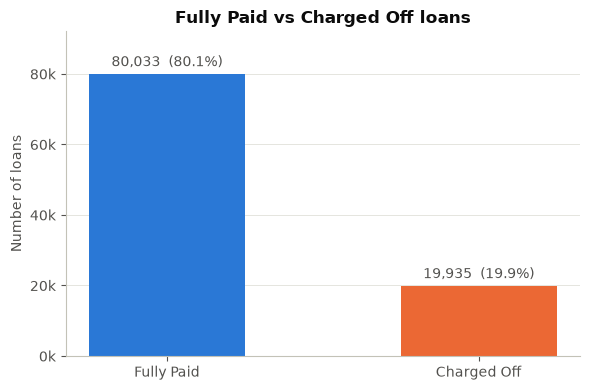

In [18]:
counts = df['loan_status'].value_counts()[['Fully Paid', 'Charged Off']]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[BLUE, ORANGE], width=0.5)
ax.bar_label(bars, labels=[f'{v:,}  ({v / len(df):.1%})' for v in counts.values], padding=3, color=GREY_TEXT)
ax.set(title='Fully Paid vs Charged Off loans', ylabel='Number of loans', ylim=(0, counts.max() * 1.15))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1e3:.0f}k'))
save('03_target_distribution')

**Observation:** about **80% of loans are fully paid and 20% are charged off**. The data is **imbalanced**: a model could reach
80% accuracy just by predicting "Fully Paid" for everyone. This is why we use class weights and look at recall and
ROC-AUC, not only accuracy.

### 4.2 Default rate by loan grade

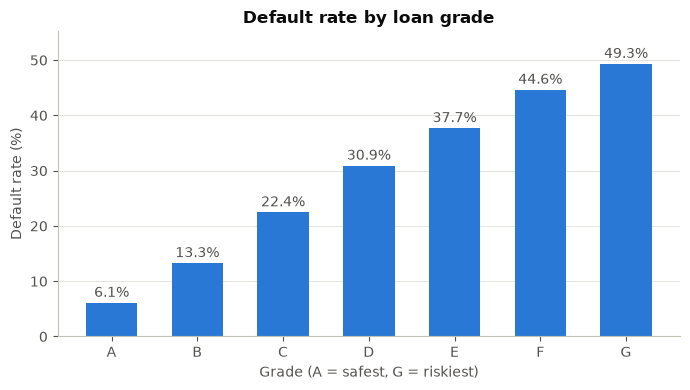

grade,A,B,C,D,E,F,G
default rate %,6.1,13.3,22.4,30.9,37.7,44.6,49.3


In [19]:
rate = df.groupby('grade')['default'].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index, rate.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt='%.1f%%', padding=2, color=GREY_TEXT)
ax.set(title='Default rate by loan grade', xlabel='Grade (A = safest, G = riskiest)', ylabel='Default rate (%)')
save('04_default_rate_by_grade')
rate.round(1).to_frame('default rate %').T

**Observation:** default rate rises steadily with grade, from **6.1% for grade A to 49.3% for grade G**.
A grade G loan is about 8 times riskier than a grade A loan, so Lending Club's grade is a strong risk signal.

### 4.3 Interest rate, FICO score and DTI: defaulters vs non-defaulters

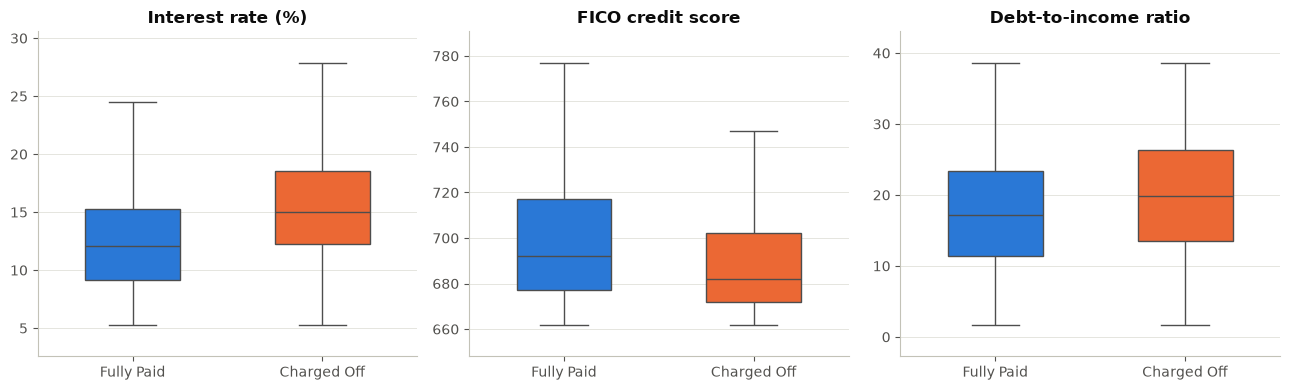

,int_rate,fico_score,dti,annual_inc,loan_amnt
loan_status,,,,,
Charged Off,15.0,682.0,19.8,60000.0,14300.0
Fully Paid,12.1,692.0,17.1,65000.0,12000.0


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in zip(axes, ['int_rate', 'fico_score', 'dti'],
                          ['Interest rate (%)', 'FICO credit score', 'Debt-to-income ratio']):
    sns.boxplot(data=df, x='loan_status', y=col, hue='loan_status', order=['Fully Paid', 'Charged Off'],
                palette=STATUS_COLORS, saturation=1, showfliers=False, width=0.5, legend=False, ax=ax)
    ax.set(title=title, xlabel='', ylabel='')
save('05_boxplots_by_status')

df.groupby('loan_status')[['int_rate', 'fico_score', 'dti', 'annual_inc', 'loan_amnt']].median().round(1)

**Observation:** compared with borrowers who repaid, defaulters had a **higher interest rate** (median 15.0% vs 12.1%),
a **lower FICO score** (682 vs 692) and a **higher DTI** (19.8 vs 17.1). They also earned a little less (median $60,000 vs $65,000)
and borrowed more ($14,300 vs $12,000). The boxes overlap a lot, so no single feature can separate the two groups on its own.

### 4.4 Default rate by loan term and home ownership

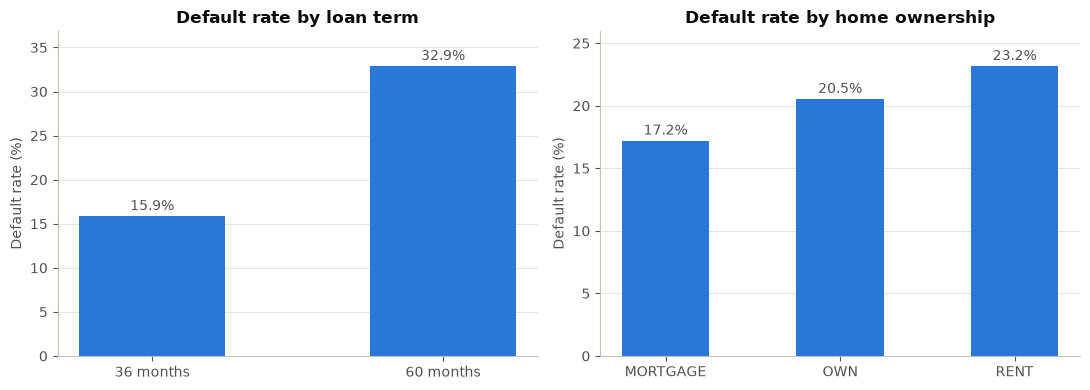

,% of loans
term,
36,76.0
60,24.0


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

rate = df.groupby('term')['default'].mean() * 100
bars = axes[0].bar([f'{t} months' for t in rate.index], rate.values, color=BLUE, width=0.5)
axes[0].bar_label(bars, fmt='%.1f%%', padding=2, color=GREY_TEXT)
axes[0].set(title='Default rate by loan term', ylabel='Default rate (%)')

rate = df.groupby('home_ownership')['default'].mean() * 100
bars = axes[1].bar(rate.index, rate.values, color=BLUE, width=0.5)
axes[1].bar_label(bars, fmt='%.1f%%', padding=2, color=GREY_TEXT)
axes[1].set(title='Default rate by home ownership', ylabel='Default rate (%)')
save('06_default_rate_term_home')

df['term'].value_counts(normalize=True).mul(100).round(1).to_frame('% of loans')

**Observation:** **60-month loans default about twice as often as 36-month loans (32.9% vs 15.9%)**, even though they are only
24% of all loans. Renters default more often (23.2%) than home owners (20.5%) and borrowers with a mortgage (17.2%).

### 4.5 Default rate by loan purpose

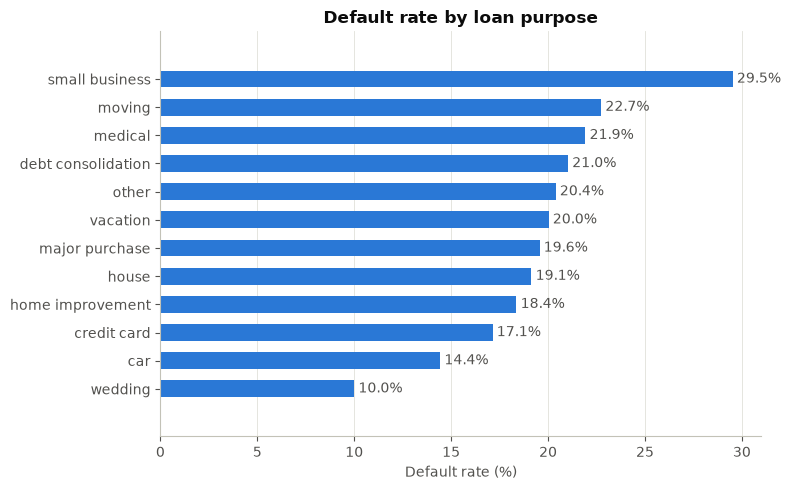

,default rate %,loans
purpose,,
small_business,29.5,1165
moving,22.7,708
medical,21.9,1131
debt_consolidation,21.0,57778
other,20.4,5801
vacation,20.0,669
major_purchase,19.6,2270
house,19.1,538
home_improvement,18.4,6516


In [22]:
purpose = df.groupby('purpose')['default'].agg(['mean', 'count'])
purpose = purpose[purpose['count'] >= 100].sort_values('mean')   # skip purposes with very few loans
purpose['mean'] *= 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(purpose.index.str.replace('_', ' '), purpose['mean'], color=BLUE, height=0.6)
ax.bar_label(bars, fmt='%.1f%%', padding=3, color=GREY_TEXT)
ax.set(title='Default rate by loan purpose', xlabel='Default rate (%)')
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
save('07_default_rate_by_purpose')

purpose.round(1).rename(columns={'mean': 'default rate %', 'count': 'loans'}).sort_values('default rate %', ascending=False)

**Observation:** **small-business loans are the riskiest** (29.5% default rate). Wedding (10.0%), car (14.4%) and credit-card (17.1%)
loans are the safest. Debt consolidation is by far the most common purpose (57,778 loans, 58% of the sample) and sits close to
the average at 21.0%. Purposes with fewer than 100 loans (educational, renewable energy) are not shown because their rates are unreliable.

### 4.6 Correlation between numeric features

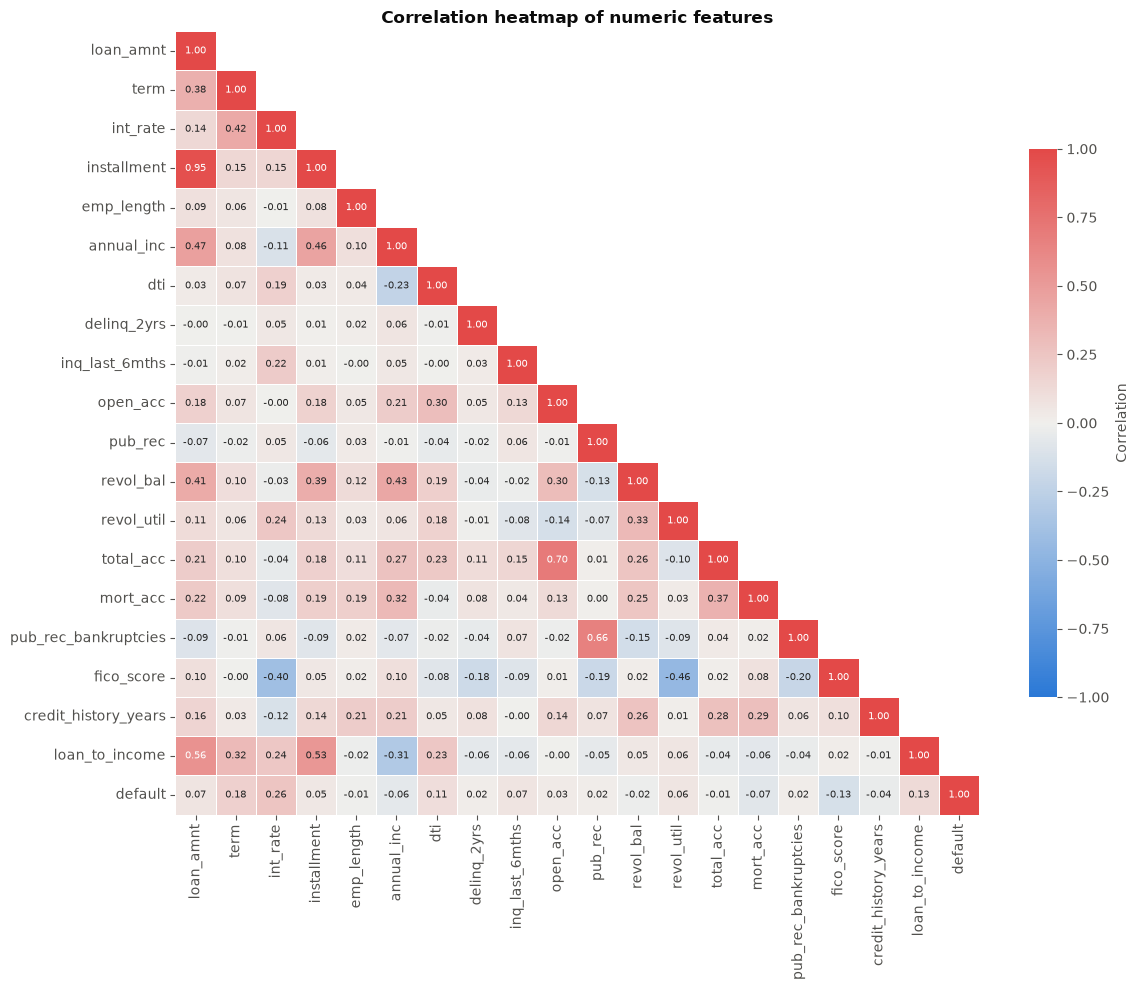

In [23]:
corr = df.select_dtypes('number').corr()
order = [c for c in corr.columns if c != 'default'] + ['default']   # put the target last
corr = corr.loc[order, order]
diverging = LinearSegmentedColormap.from_list('blue_red', [BLUE, '#f0efec', RED])

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=diverging, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, linecolor='white',
            cbar_kws={'shrink': 0.7, 'label': 'Correlation'}, ax=ax)
ax.set_title('Correlation heatmap of numeric features')
ax.grid(False)
save('08_correlation_heatmap')

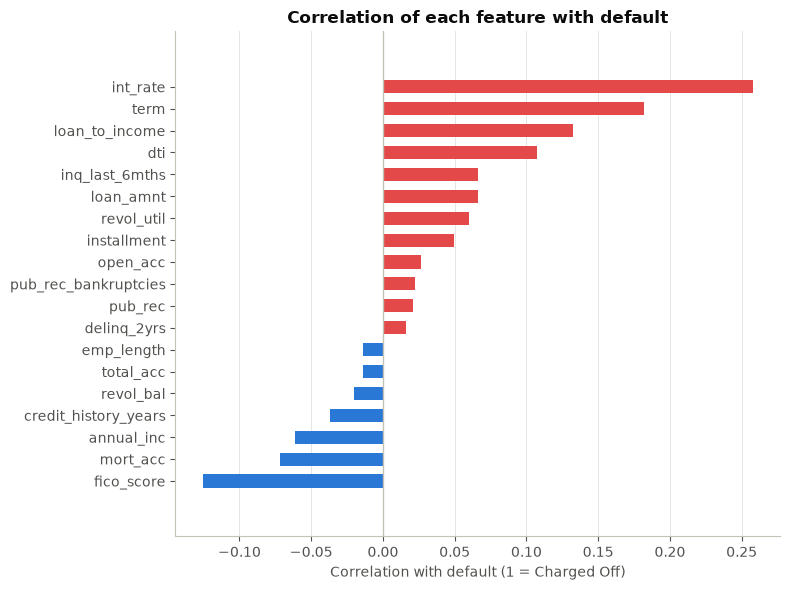

,correlation with default
int_rate,0.258
term,0.182
loan_to_income,0.132
fico_score,-0.125
dti,0.108
mort_acc,-0.072
inq_last_6mths,0.066
loan_amnt,0.066


In [24]:
target_corr = corr['default'].drop('default').sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(target_corr.index, target_corr.values, color=[RED if v > 0 else BLUE for v in target_corr.values], height=0.6)
ax.axvline(0, color='#c3c2b7', lw=1)
ax.set(title='Correlation of each feature with default', xlabel='Correlation with default (1 = Charged Off)')
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
save('09_correlation_with_default')

target_corr.sort_values(key=abs, ascending=False).round(3).to_frame('correlation with default').head(8)

**Observation:** no feature is strongly correlated with default on its own. The strongest is **interest rate (0.26)**,
followed by term (0.18), loan-to-income (0.13) and FICO score (−0.13: a higher score means lower risk).
Some features are strongly related to each other: loan amount and installment (0.95), open accounts and total accounts (0.70),
and public records and bankruptcies (0.66). FICO score goes down as interest rate (−0.40) and revolving utilisation (−0.46) go up.

## 5. Statistical analysis (sampling and estimation)

Our 100,000 loans are a **sample** of the 1.35 million finished loans. This section checks how sure we can be about
values estimated from the sample, and which differences between defaulters and non-defaulters are real.

### 5.1 Confidence intervals (95%)

A 95% confidence interval gives a range that very likely contains the true value for **all** loans:
- for a proportion (default rate): p ± 1.96 × √(p(1 − p) / n)
- for an average: mean ± 1.96 × standard deviation / √n

In [25]:
n = len(df)
p = df['default'].mean()
se = np.sqrt(p * (1 - p) / n)
ci_rows = [{'Value': 'Default rate (%)', 'Estimate': p * 100,
            'Lower 95%': (p - 1.96 * se) * 100, 'Upper 95%': (p + 1.96 * se) * 100}]

for col, label in [('int_rate', 'Average interest rate (%)'), ('loan_amnt', 'Average loan amount ($)'),
                   ('fico_score', 'Average FICO score')]:
    mean, se = df[col].mean(), df[col].std() / np.sqrt(n)
    ci_rows.append({'Value': label, 'Estimate': mean, 'Lower 95%': mean - 1.96 * se, 'Upper 95%': mean + 1.96 * se})

ci_table = pd.DataFrame(ci_rows).set_index('Value').round(2)

# The full file tells us the true default rate of all finished loans, so we can check the interval
full_counts = status.set_index('loan_status')['count']
finished = full_counts['Charged Off'] + full_counts['Fully Paid']
print(f'True default rate of all {finished:,} finished loans: {full_counts["Charged Off"] / finished * 100:.2f}%')
ci_table

True default rate of all 1,345,310 finished loans: 19.96%


,Estimate,Lower 95%,Upper 95%
Value,,,
Default rate (%),19.94,19.69,20.19
Average interest rate (%),13.24,13.21,13.27
Average loan amount ($),14414.31,14360.15,14468.46
Average FICO score,698.17,697.98,698.37


**Observation:** the sample default rate is **19.94%**, with a 95% confidence interval of **19.69% to 20.19%**.
The true default rate of all 1,345,310 finished loans is **19.96%**, which is inside the interval, so the 100,000-loan sample
represents the full data well. Because the sample is large, the intervals are narrow (for example, the average interest rate is 13.24% ± 0.03%).

### 5.2 Random vs stratified sampling

We take 200 small samples of 1,000 loans in two ways and look at the default rate of each sample:
- **Random sampling:** pick any 1,000 loans.
- **Stratified sampling:** pick 20% defaulters and 80% non-defaulters, the same split as the data.

Random samples:     default rate from 16.7% to 23.7%
Stratified samples: default rate from 19.9% to 19.9%


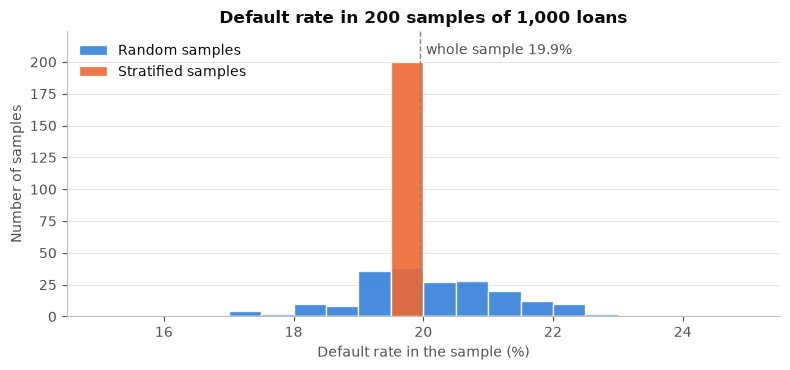

In [26]:
random_rates, stratified_rates = [], []
for i in range(200):
    random_rates.append(df.sample(1000, random_state=i)['default'].mean() * 100)
    stratified = df.groupby('default', group_keys=False).sample(frac=1000 / len(df), random_state=i)
    stratified_rates.append(stratified['default'].mean() * 100)

print(f'Random samples:     default rate from {min(random_rates):.1f}% to {max(random_rates):.1f}%')
print(f'Stratified samples: default rate from {min(stratified_rates):.1f}% to {max(stratified_rates):.1f}%')

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(15, 25.5, 0.5)
ax.hist(random_rates, bins=bins, color=BLUE, alpha=0.85, label='Random samples', edgecolor='white')
ax.hist(stratified_rates, bins=bins, color=ORANGE, alpha=0.9, label='Stratified samples', edgecolor='white')
ax.axvline(p * 100, color=GREY_LINE, ls='--', lw=1)
ax.text(p * 100 + 0.1, ax.get_ylim()[1] * 0.92, f'whole sample {p * 100:.1f}%', color=GREY_TEXT)
ax.set(title='Default rate in 200 samples of 1,000 loans', xlabel='Default rate in the sample (%)', ylabel='Number of samples')
ax.legend(loc='upper left')
save('10_sampling_experiment')

**Sample size:** how many loans would we need to estimate the default rate within a chosen margin of error E (95% confidence)?
n = 1.96² × p(1 − p) / E²

In [27]:
for margin in [0.03, 0.02, 0.01]:
    n_needed = 1.96 ** 2 * p * (1 - p) / margin ** 2
    print(f'Within ±{margin * 100:.0f}%: {int(np.ceil(n_needed)):,} loans')

Within ±3%: 682 loans
Within ±2%: 1,534 loans
Within ±1%: 6,134 loans


**Observation:** with random sampling, the default rate of a 1,000-loan sample changed from **16.7% to 23.7%** just by chance.
Stratified sampling kept it at **19.9% every time**. This is why the train/test split uses `stratify=y`.
To estimate the default rate within ±3% we would need only **682 loans**, and within ±1% only **6,134 loans**,
so our 100,000 loans are more than enough.

### 5.3 Hypothesis tests (α = 0.05)

**Null hypothesis (H₀):** the feature is the same for defaulters and non-defaulters.
- Numeric features: **Welch t-test** (are the two averages different?)
- Categories: **chi-square test** (does the default rate depend on the category?)

If p < 0.05, we reject H₀: the difference is real and not just chance.

In [28]:
defaulted, repaid = df[df['default'] == 1], df[df['default'] == 0]
tests = []
for col in ['int_rate', 'fico_score', 'dti', 'annual_inc', 'loan_to_income', 'emp_length']:
    t_stat, p_value = stats.ttest_ind(defaulted[col], repaid[col], equal_var=False)
    tests.append({'Feature': col, 'Test': 't-test', 'Mean (defaulted)': defaulted[col].mean(),
                  'Mean (repaid)': repaid[col].mean(), 'p-value': p_value})
for col in ['term', 'grade', 'home_ownership', 'verification_status', 'purpose', 'application_type']:
    chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(df[col], df['default']))
    tests.append({'Feature': col, 'Test': 'chi-square', 'p-value': p_value})

tests = pd.DataFrame(tests)
tests['Significant?'] = np.where(tests['p-value'] < 0.05, 'Yes', 'No')
tests['p-value'] = tests['p-value'].map(lambda v: '< 0.001' if v < 0.001 else f'{v:.3f}')
tests.round(2)

,Feature,Test,Mean (defaulted),Mean (repaid),p-value,Significant?
0,int_rate,t-test,15.71,12.63,< 0.001,Yes
1,fico_score,t-test,690.17,700.17,< 0.001,Yes
2,dti,t-test,19.97,17.69,< 0.001,Yes
3,annual_inc,t-test,69393.62,75916.26,< 0.001,Yes
4,loan_to_income,t-test,0.25,0.21,< 0.001,Yes
5,emp_length,t-test,5.88,6.00,< 0.001,Yes
6,term,chi-square,NaN,NaN,< 0.001,Yes
7,grade,chi-square,NaN,NaN,< 0.001,Yes
8,home_ownership,chi-square,NaN,NaN,< 0.001,Yes
9,verification_status,chi-square,NaN,NaN,< 0.001,Yes


With almost 100,000 loans, even very small differences become statistically significant. So we also look at
**how big** the difference is (Section 4), not only at the p-value. To see this, we repeat the t-test on a
small random sample of 500 loans:

In [29]:
small = df.sample(500, random_state=1)
for col in ['int_rate', 'emp_length']:
    t_stat, p_value = stats.ttest_ind(small.loc[small['default'] == 1, col], small.loc[small['default'] == 0, col],
                                      equal_var=False)
    print(f'{col:12s} p-value with 500 loans: {p_value:.3f}', '(significant)' if p_value < 0.05 else '(not significant)')

int_rate     p-value with 500 loans: 0.000 (significant)
emp_length   p-value with 500 loans: 0.112 (not significant)


**Observation:** all 12 features show a significant difference between defaulters and non-defaulters (p < 0.001), so H₀ is rejected
for each of them. Defaulters have a higher average interest rate (15.7% vs 12.6%), a lower FICO score (690 vs 700), a higher DTI
(20.0 vs 17.7) and a lower income. But with 100,000 loans even tiny differences become significant: employment length differs by only
0.1 years (5.9 vs 6.0). With just 500 loans, the same test is **not** significant for employment length (p = 0.112) but still is for
interest rate (p < 0.001). Statistical significance does not always mean a difference is important.

## 6. Encoding, train/test split and scaling

- **Grade** has a natural order, so A to G becomes 1 to 7.
- **Home ownership, verification status, purpose and application type** have no order, so they are
  **one-hot encoded** (one 0/1 column per category).
- **Train/test split:** 80% for training, 20% for testing. `stratify=y` keeps the same 20% default rate in both parts.
- **Scaling:** `StandardScaler` puts all numbers on the same scale (mean 0, standard deviation 1). Logistic Regression needs this;
  tree models do not, but it does not hurt them, so all three models use the same data. The scaler is fitted on the
  training data only, so no information from the test set leaks into training.

In [30]:
model_df = df.drop(columns=['loan_status']).copy()
model_df['grade'] = model_df['grade'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7})
model_df = pd.get_dummies(model_df, columns=['home_ownership', 'verification_status', 'purpose', 'application_type'],
                          drop_first=True, dtype=int)

X = model_df.drop(columns=['default'])
y = model_df['default']
print('Features used by the models:', X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training rows:', len(X_train), '| default rate:', round(y_train.mean() * 100, 1), '%')
print('Testing rows: ', len(X_test), '| default rate:', round(y_test.mean() * 100, 1), '%')

Features used by the models: 38


Training rows: 79974 | default rate: 19.9 %
Testing rows:  19994 | default rate: 19.9 %


## 7. Models

Three models, from simple to more powerful:

| Model | Why it is used |
|---|---|
| Logistic Regression | simple, fast baseline |
| Random Forest | many decision trees combined; captures non-linear patterns |
| XGBoost | boosted trees; usually the strongest on tabular data |

**Class imbalance:** only about 20% of loans default. Without help, a model can get 80% accuracy by predicting
"everyone pays" and never catch a defaulter. We use **class weights** so that mistakes on defaulters count more:
`class_weight='balanced'` for Logistic Regression and Random Forest, and `scale_pos_weight` for XGBoost.

**Cross-validation:** before testing, each model is also checked with **5-fold cross-validation** on the training data
(train on 4/5, check on the other 1/5, five times). A stable CV score means the result does not depend on one lucky split.

In [31]:
baseline_pred = np.zeros(len(y_test))
print('Baseline "everyone pays" accuracy:', round(accuracy_score(y_test, baseline_pred), 3),
      '| defaulters caught:', int(baseline_pred[y_test == 1].sum()))

Baseline "everyone pays" accuracy: 0.801 | defaulters caught: 0


In [32]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()   # about 4 paid loans for every default
print('scale_pos_weight for XGBoost:', round(ratio, 2))

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=20,
                                            class_weight='balanced', n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=ratio, n_jobs=-1, random_state=42),
}

results, probs = [], {}
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='roc_auc').mean()
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    prob = model.predict_proba(X_test_scaled)[:, 1]   # probability of default
    probs[name] = prob
    results.append({
        'Model': name,
        'CV ROC-AUC': cv_auc,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
        'Train ROC-AUC': roc_auc_score(y_train, model.predict_proba(X_train_scaled)[:, 1]),
    })
    print(name, 'trained')

results = pd.DataFrame(results).set_index('Model').round(3)
results

scale_pos_weight for XGBoost: 4.01


Logistic Regression trained


Random Forest trained


XGBoost trained


,CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC-AUC,Train ROC-AUC
Model,,,,,,,
Logistic Regression,0.709,0.660,0.322,0.639,0.428,0.713,0.710
Random Forest,0.712,0.647,0.316,0.662,0.428,0.712,0.766
XGBoost,0.716,0.648,0.317,0.664,0.429,0.716,0.746


**Observation:** the three models score almost the same: **ROC-AUC 0.712–0.716** and **recall 0.64–0.66**, so they catch about
two out of every three defaulters. The 5-fold **CV ROC-AUC (0.709–0.716)** is almost the same as the test ROC-AUC, so the results are
stable and do not depend on one lucky split. Precision is low (about 0.32): of the loans flagged as risky, about one in three really defaults.
Accuracy (about 0.65) is below the 0.80 "everyone pays" baseline, but that baseline catches **zero** defaulters, so it is useless.
Random Forest shows the biggest gap between training and test ROC-AUC (0.766 vs 0.712), a sign of mild overfitting;
Logistic Regression has no gap.

## 8. Results and comparison

### 8.1 Metric comparison

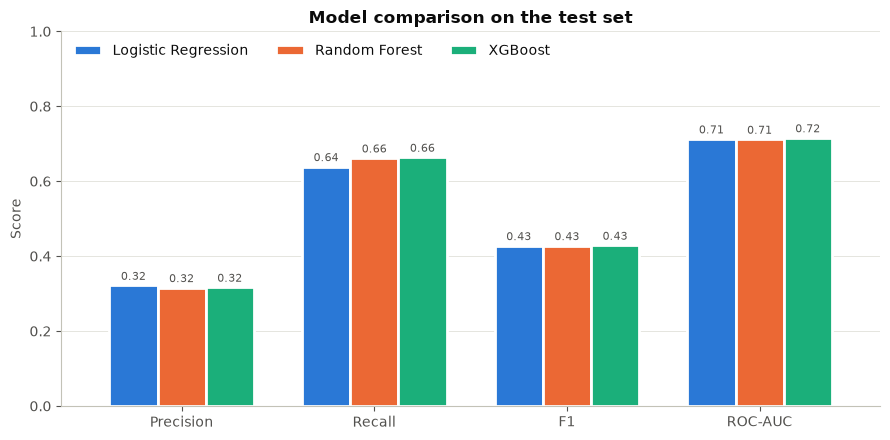

In [33]:
ax = results[['Precision', 'Recall', 'F1', 'ROC-AUC']].T.plot(
    kind='bar', figsize=(9, 4.5), color=[BLUE, ORANGE, AQUA], width=0.75, edgecolor='white', linewidth=2, rot=0)
ax.set(title='Model comparison on the test set', ylabel='Score', ylim=(0, 1))
ax.legend(loc='upper left', ncols=3)
ax.grid(axis='x', visible=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=8, color=GREY_TEXT)
save('11_model_comparison')

### 8.2 ROC curves and precision-recall curves

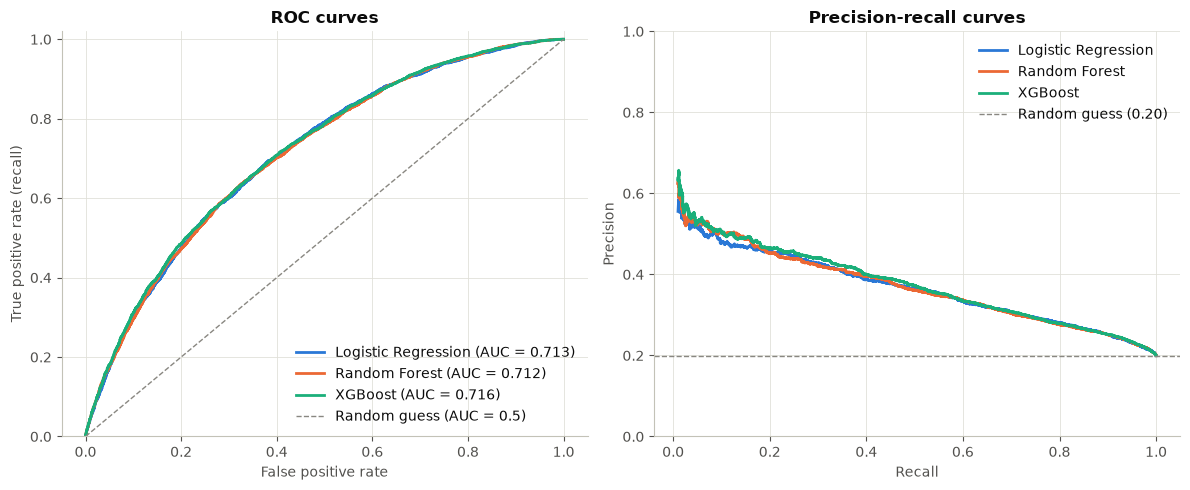

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for (name, prob), color in zip(probs.items(), [BLUE, ORANGE, AQUA]):
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
    precision, recall, _ = precision_recall_curve(y_test, prob)
    keep = recall > 0.01   # skip the first few points, which are very noisy
    axes[1].plot(recall[keep], precision[keep], color=color, lw=2, label=name)

axes[0].plot([0, 1], [0, 1], ls='--', color=GREY_LINE, lw=1, label='Random guess (AUC = 0.5)')
axes[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate (recall)', ylim=(0, 1.02))
axes[0].legend(loc='lower right')

axes[1].axhline(y_test.mean(), ls='--', color=GREY_LINE, lw=1, label=f'Random guess ({y_test.mean():.2f})')
axes[1].set(title='Precision-recall curves', xlabel='Recall', ylabel='Precision', ylim=(0, 1))
axes[1].legend(loc='upper right')

for ax in axes:
    ax.grid(True)
save('12_roc_pr_curves')

**Observation:** the three ROC curves lie almost on top of each other, well above the random-guess line.
On the precision-recall curve all models stay above the 0.20 random baseline. If we flag only the riskiest few loans,
precision is around 0.5, but it falls as we try to catch more defaulters. A lender would choose the balance by moving the
decision threshold.

### 8.3 Confusion matrix of the best model

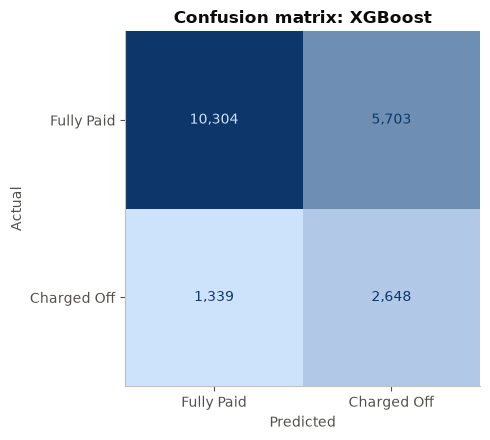

Defaulters correctly caught (TP):        2,648 of 3,987  (66%)
Defaulters missed (FN):                   1,339
Good borrowers wrongly flagged (FP):      5,703 of 16,007  (36%)
Good borrowers correctly approved (TN):   10,304


In [35]:
best = results['ROC-AUC'].idxmax()
pred = models[best].predict(X_test_scaled)
cm = confusion_matrix(y_test, pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
blues = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#0d366b'])
ConfusionMatrixDisplay(cm, display_labels=['Fully Paid', 'Charged Off']).plot(
    cmap=blues, colorbar=False, values_format=',', ax=ax)
ax.set(title=f'Confusion matrix: {best}', xlabel='Predicted', ylabel='Actual')
ax.grid(False)
save('13_confusion_matrix')

tn, fp, fn, tp = cm.ravel()
print(f'Defaulters correctly caught (TP):        {tp:,} of {tp + fn:,}  ({tp / (tp + fn):.0%})')
print(f'Defaulters missed (FN):                   {fn:,}')
print(f'Good borrowers wrongly flagged (FP):      {fp:,} of {tn + fp:,}  ({fp / (tn + fp):.0%})')
print(f'Good borrowers correctly approved (TN):   {tn:,}')

**Observation:** XGBoost (the best model by ROC-AUC) correctly flags **2,648 of the 3,987 defaulters (66%)** in the test set and misses 1,339.
The cost is 5,703 good borrowers (36%) wrongly flagged as risky. A higher threshold would flag fewer good borrowers but miss more defaulters.

## 9. Feature importance (XGBoost)

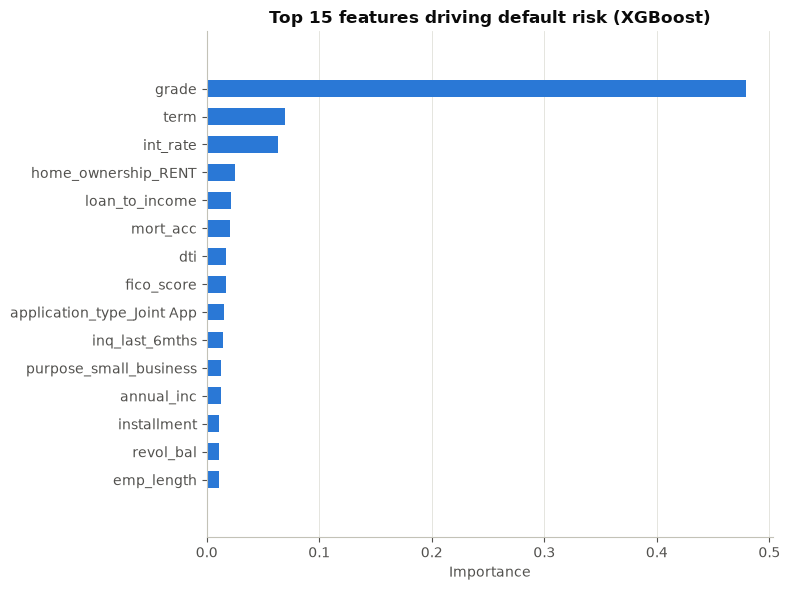

,importance
grade,0.480
term,0.069
int_rate,0.064
home_ownership_RENT,0.025
loan_to_income,0.021
mort_acc,0.021
dti,0.017
fico_score,0.017
application_type_Joint App,0.015
inq_last_6mths,0.014


In [36]:
importance = pd.Series(models['XGBoost'].feature_importances_, index=X.columns).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set(title='Top 15 features driving default risk (XGBoost)', xlabel='Importance')
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
save('14_feature_importance')

importance.sort_values(ascending=False).round(3).to_frame('importance').head(10)

**Observation:** **grade is by far the most important feature (0.48)**, followed by term (0.07) and interest rate (0.06).
Grade and interest rate are Lending Club's own risk rating, so the model largely agrees with it.
Next come renting a home, loan-to-income (a feature we created), number of mortgage accounts, DTI and FICO score.
This matches what we saw in the EDA.

## 10. Business impact: loan approval strategy

How would a lender use the model? The best model gives every test loan a probability of default.
We sort the loans from riskiest to safest and **reject the riskiest X%**, then check:
- what share of the real defaulters we stopped,
- what share of good borrowers we turned away,
- the default rate of the loans we still approve (compared with 19.9% if we approve everyone).

In [37]:
y_true = y_test.values
order = np.argsort(-probs[best])          # riskiest loans first
y_sorted = y_true[order]

strategy = [{'Reject riskiest': '0% (approve everyone)', 'Defaulters stopped (%)': 0.0, 'Good borrowers rejected (%)': 0.0,
             'Default rate of approved loans (%)': y_true.mean() * 100, 'Better than random (x)': np.nan}]
for pct in [10, 20, 30, 40, 50]:
    k = int(len(y_sorted) * pct / 100)
    rejected, approved = y_sorted[:k], y_sorted[k:]
    stopped = rejected.sum() / y_sorted.sum()
    strategy.append({'Reject riskiest': f'{pct}%',
                     'Defaulters stopped (%)': stopped * 100,
                     'Good borrowers rejected (%)': (rejected == 0).sum() / (y_sorted == 0).sum() * 100,
                     'Default rate of approved loans (%)': approved.mean() * 100,
                     'Better than random (x)': stopped / (pct / 100)})
strategy = pd.DataFrame(strategy).set_index('Reject riskiest').round(1)
strategy

,Defaulters stopped (%),Good borrowers rejected (%),Default rate of approved loans (%),Better than random (x)
Reject riskiest,,,,
0% (approve everyone),0.0,0.0,19.9,NaN
10%,22.8,6.8,17.1,2.3
20%,40.1,15.0,14.9,2.0
30%,53.7,24.1,13.2,1.8
40%,64.6,33.9,11.8,1.6
50%,74.1,44.0,10.3,1.5


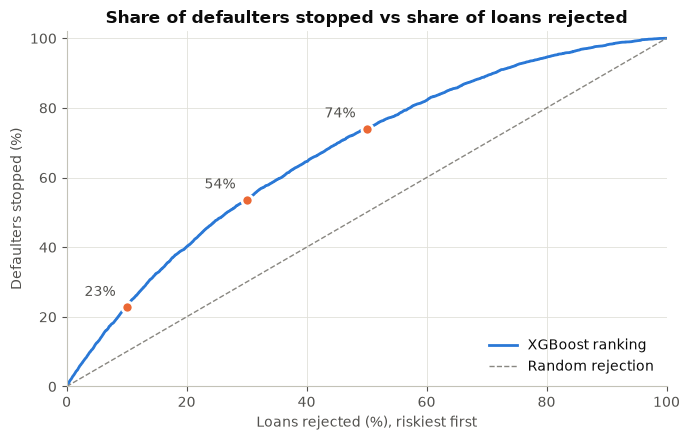

In [38]:
rejected_share = np.arange(1, len(y_sorted) + 1) / len(y_sorted) * 100
stopped_share = np.cumsum(y_sorted) / y_sorted.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(rejected_share, stopped_share, color=BLUE, lw=2, label=f'{best} ranking')
ax.plot([0, 100], [0, 100], ls='--', color=GREY_LINE, lw=1, label='Random rejection')
for pct in [10, 30, 50]:
    value = stopped_share[int(len(y_sorted) * pct / 100) - 1]
    ax.plot(pct, value, 'o', color=ORANGE, ms=8, markeredgecolor='white', markeredgewidth=2)
    ax.annotate(f'{value:.0f}%', (pct, value), textcoords='offset points', xytext=(-8, 8), ha='right', color=GREY_TEXT)
ax.set(title='Share of defaulters stopped vs share of loans rejected', xlabel='Loans rejected (%), riskiest first',
       ylabel='Defaulters stopped (%)', xlim=(0, 100), ylim=(0, 102))
ax.grid(True)
ax.legend(loc='lower right')
save('15_approval_strategy')

**Observation:** rejecting only the riskiest **10%** of applications stops **22.8%** of defaulters, 2.3 times better than rejecting at random.
Rejecting the riskiest **30%** stops **53.7%** of defaulters and lowers the default rate of approved loans from **19.9% to 13.2%**,
but it also turns away 24.1% of good borrowers. The lender would choose the cut-off based on how much a default costs compared with
losing a good customer. The dashboard lets you try any cut-off.

## 11. Save the results for the dashboard

The Streamlit dashboard (`app.py`) does not retrain anything. It loads:
- `data/loans_clean.csv`: the cleaned data (for the charts)
- `models/loan_models.pkl`: the three trained models, the scaler, the feature list and the test results

In [39]:
os.makedirs('models', exist_ok=True)
df.to_csv('data/loans_clean.csv', index=False)
joblib.dump({
    'models': models,
    'scaler': scaler,
    'feature_columns': list(X.columns),
    'results': results,
    'best_model': best,
    'y_test': y_test.values,
    'probs': probs,
    'importance': pd.Series(models['XGBoost'].feature_importances_, index=X.columns),
}, 'models/loan_models.pkl')

print('Saved data/loans_clean.csv:', df.shape)
print('Saved models/loan_models.pkl:', round(os.path.getsize('models/loan_models.pkl') / 1e6, 1), 'MB')

Saved data/loans_clean.csv: (99968, 26)
Saved models/loan_models.pkl: 16.8 MB


## 12. Summary

- **Data:** 100,000 finished loans, reduced from 151 columns to 26 clean columns (38 model features after encoding).
- **Statistics:** the sample default rate (19.94%, 95% CI 19.69–20.19%) contains the true rate of all 1.35 million loans (19.96%).
  Stratified sampling keeps the default rate fixed, so it was used for the train/test split.
- **Best model:** XGBoost with ROC-AUC **0.716** (CV 0.716) and recall **0.66**, but all three models are almost equal.
- **Main drivers of default:** loan grade, loan term, interest rate, loan-to-income ratio, DTI and FICO score.
- **Business impact:** rejecting the riskiest 30% of applications stops 54% of defaulters and lowers the default rate of approved loans
  from 19.9% to 13.2%.
- **Data leakage** was the biggest trap: columns such as `recoveries` and `total_pymnt` are only known after the loan ends,
  and keeping them would give fake, near-perfect scores.
- **Dashboard:** `streamlit run app.py` opens a 5-page dashboard built from the files saved in Section 11.
- **Next steps:** tune the decision threshold, try SMOTE, tune hyper-parameters with GridSearchCV, add SHAP explanations,
  and deploy the dashboard online.